# 03 · Implied volatility smile from real option prices

Black-Scholes has five inputs. Four are observable: spot, strike, time and the interest rate. **Volatility is not.** So traders run the formula backwards: given an option's market price, find the volatility that reproduces it. That number is the **implied volatility (IV)**, and it is how options are actually quoted and compared.

If Black-Scholes were exactly right, every option on the same stock would have the same IV. In reality IV varies with strike (the **smile** or **skew**) and with expiry (the **term structure**). Measuring that is the first thing an options desk does every morning.

**Pipeline**
1. Download bid/ask quotes for calls and puts across strikes and expiries.
2. Clean them: drop zero bids, crossed markets and very wide spreads.
3. For each expiry, read the **forward** $F$ and **discount factor** $DF$ directly from **put-call parity**, $C - P = DF\,(F - K)$: regress $C - P$ on $K$; slope $= -DF$, intercept $= DF \cdot F$. No need to guess rates or dividends.
4. Keep **out-of-the-money** options only (puts below $F$, calls above): they are the most liquid and carry almost no early-exercise premium (SPY options are American-style).
5. Solve for IV with Brent's root-finder on the Black (1976) formula.

**Part A** validates the pipeline on synthetic data with a known answer. **Part B** runs it on live SPY (S&P 500 ETF) options; it needs internet, so run it in Google Colab.

In [7]:
# --- Setup: works both locally and in Google Colab ---
import os, sys
IN_COLAB = "google.colab" in sys.modules
REPO_DIR = "/content/options-pricing-hedging-lab"
if IN_COLAB and not os.path.isdir(REPO_DIR):
    user = input("GitHub username that hosts this repo: ").strip()
    os.system(f"git clone -q https://github.com/{user}/options-pricing-hedging-lab.git {REPO_DIR}")
    if not os.path.isdir(REPO_DIR):
        raise RuntimeError(f"Could not clone github.com/{user}/options-pricing-hedging-lab - check the username and that the repo is public.")
if IN_COLAB:
    os.chdir(f"{REPO_DIR}/notebooks")
sys.path.insert(0, os.path.abspath("../src"))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from optionslab import *
from optionslab.plotting import use_style, save, SERIES, BLUE, ORANGE, AQUA, YELLOW, INK, INK_2, MUTED

use_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
from optionslab.market_data import (make_synthetic_chain, clean_quotes, estimate_forward,
                                    compute_smile, atm_term_structure, fetch_yahoo_chain, default_smile)

## Part A · Does the pipeline recover a smile we already know?

We generate quotes from a known smile (with realistic bid-ask spreads and noise), push them through the pipeline as if they were real, and compare. A pipeline that cannot recover a known answer cannot be trusted on real data.

What to look for: the forward $F$ should come back almost exactly, the discount factor to about 3-4 decimals (small errors there barely move IV), and every implied vol within a fraction of a vol point of the truth.

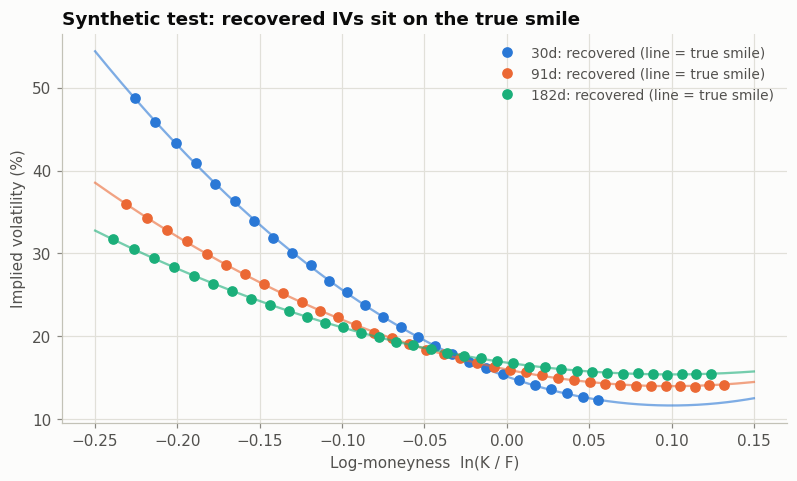

,expiry,F recovered,F true,DF recovered,DF true,max |IV error| (vol pts)
0,30d,100.2620,100.2634,0.9957,0.9963,0.2094
1,91d,100.8029,100.8010,0.9879,0.9888,0.1653
2,182d,101.5994,101.6084,0.9776,0.9778,0.1504


In [8]:
true_r, true_q, spot_syn = 0.045, 0.013, 100.0
synthetic = make_synthetic_chain(spot=spot_syn, r=true_r, q=true_q, seed=0)
smile_syn = compute_smile(clean_quotes(synthetic), spot_syn)

rows = []
for exp, grp in smile_syn.groupby("expiry", sort=False):
    T_ = grp["T"].iloc[0]
    rows.append({"expiry": exp,
                 "F recovered": grp["F"].iloc[0], "F true": spot_syn * np.exp((true_r - true_q) * T_),
                 "DF recovered": grp["DF"].iloc[0], "DF true": np.exp(-true_r * T_),
                 "max |IV error| (vol pts)": 100 * (grp["iv"] - grp["true_iv"]).abs().max()})
validation = pd.DataFrame(rows).sort_values("expiry", key=lambda s: s.str[:-1].astype(int))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
k_fine = np.linspace(-0.25, 0.15, 200)
order = sorted(smile_syn["expiry"].unique(), key=lambda e: int(e[:-1]))
for exp, color in zip(order, SERIES):
    grp = smile_syn[smile_syn.expiry == exp]
    ax.plot(k_fine, 100 * default_smile(k_fine, grp["T"].iloc[0]), color=color, lw=1.5, alpha=0.6)
    ax.plot(grp["k"], 100 * grp["iv"], "o", color=color, label=f"{exp}: recovered (line = true smile)")
ax.set_xlabel("Log-moneyness  ln(K / F)")
ax.set_ylabel("Implied volatility (%)")
ax.set_title("Synthetic test: recovered IVs sit on the true smile")
ax.legend()
save(fig, "15_iv_pipeline_validation"); plt.show()
validation

## Part B · Live market data (SPY options)

This cell downloads today's SPY option chain from Yahoo Finance through the `yfinance` package. If there is no internet access (for example on a locked-down machine) it says so and the remaining cells are skipped. **Run this notebook in Google Colab to get real results**; the figures are saved into `figures/` and, in Colab, downloaded to your computer automatically.

In [9]:
TICKER = "SPY"
LIVE = False
try:
    try:
        import yfinance  # noqa: F401
    except ImportError:
        os.system(f"{sys.executable} -m pip -q install yfinance")
    spot, raw = fetch_yahoo_chain(TICKER, target_days=(30, 60, 91, 182))
    LIVE = len(raw) > 0
    asof = pd.Timestamp.now(tz="America/New_York")
    print(f"{TICKER} spot = {spot:.2f}  |  {len(raw):,} quotes  |  expiries: {', '.join(raw['expiry'].unique())}")
    print(f"Data as of {asof:%Y-%m-%d %H:%M} New York time")
except Exception as err:
    print("Could not download live data here (no internet access?).")
    print("Open this notebook in Google Colab and run all cells there to get the real smile.")
    print(f"Details: {type(err).__name__}: {err}")

SPY spot = 763.25  |  1,534 quotes  |  expiries: 2026-11-13, 2026-12-18, 2027-01-15, 2027-03-31
Data as of 2026-10-17 17:02 New York time


In [10]:
if LIVE:
    quotes = clean_quotes(raw)
    smile = compute_smile(quotes, spot)
    print(f"{len(raw):,} raw quotes -> {len(quotes):,} after cleaning -> {len(smile):,} OTM implied vols")
    per_expiry = (smile.groupby("expiry", sort=False)
                  .agg(days=("T", lambda s: s.iloc[0] * 365), forward=("F", "first"),
                       discount_factor=("DF", "first"), implied_rate=("implied_rate", "first"),
                       parity_pairs=("parity_pairs", "first"), options=("iv", "size"),
                       price_source=("price_source", "first")))
    display(per_expiry)

/content/options-pricing-hedging-lab/src/optionslab/market_data.py:165: UserWarning: 2026-11-13: skipped (implausible discount factor 1.0218 from parity regression)
  warnings.warn(f"{exp}: skipped ({err})")


1,534 raw quotes -> 1,285 after cleaning -> 557 OTM implied vols


,days,forward,discount_factor,implied_rate,parity_pairs,options,price_source
expiry,,,,,,,
2026-12-18,61.9984,766.9670,1.0188,-0.1096,86,223,mid
2027-01-15,89.9984,768.4763,1.0118,-0.0475,18,145,mid
2027-03-31,164.9567,773.6899,1.0100,-0.0221,18,189,mid


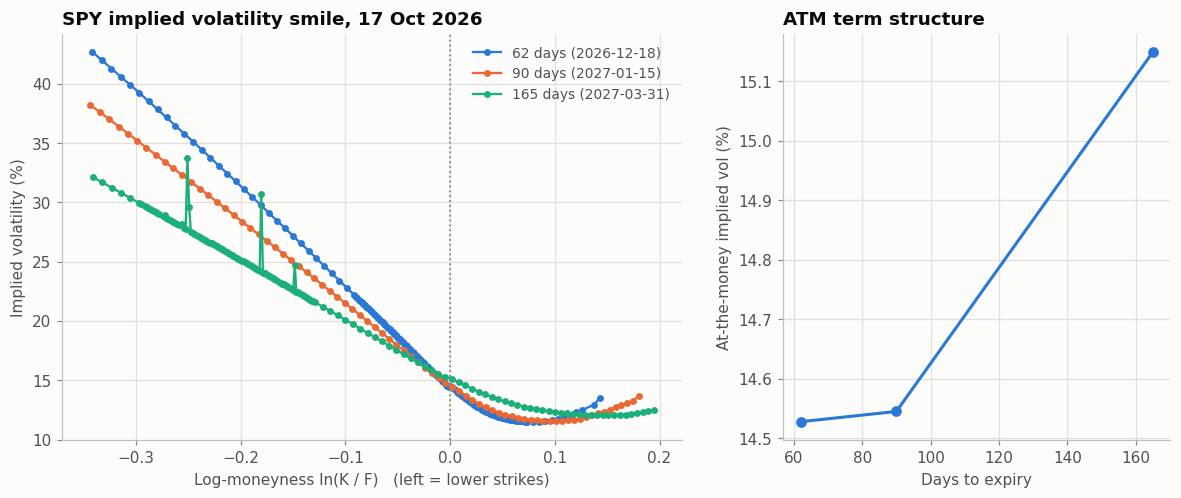

Saved ../figures/16_iv_smile_SPY.png and ../data/spy_smile_20261017.csv


In [11]:
if LIVE:
    expiries = list(dict.fromkeys(smile.sort_values("T")["expiry"]))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
    for exp, color in zip(expiries, SERIES):
        grp = smile[(smile.expiry == exp) & (smile.k.between(-0.35, 0.2))]
        days = grp["T"].iloc[0] * 365
        ax1.plot(grp["k"], 100 * grp["iv"], "o-", ms=3.5, lw=1.5, color=color, label=f"{days:.0f} days ({exp})")
    ax1.axvline(0, color=MUTED, ls=":", lw=1.2)
    ax1.set_xlabel("Log-moneyness ln(K / F)   (left = lower strikes)")
    ax1.set_ylabel("Implied volatility (%)")
    ax1.set_title(f"{TICKER} implied volatility smile, {asof:%d %b %Y}")
    ax1.legend()

    ts = atm_term_structure(smile)
    ax2.plot(ts["days"], 100 * ts["atm_iv"], "o-", color=BLUE)
    ax2.set_xlabel("Days to expiry"); ax2.set_ylabel("At-the-money implied vol (%)")
    ax2.set_title("ATM term structure")
    path = save(fig, f"16_iv_smile_{TICKER}")
    plt.show()

    os.makedirs("../data", exist_ok=True)
    csv_path = f"../data/{TICKER.lower()}_smile_{asof:%Y%m%d}.csv"
    smile.to_csv(csv_path, index=False)
    print(f"Saved {path} and {csv_path}")

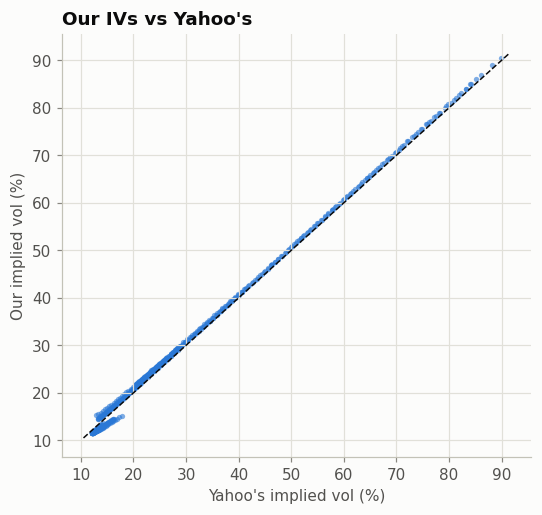

Median absolute difference: 0.85 vol points
Differences are expected: Yahoo uses its own rates, last prices and timing conventions.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
if LIVE:
    # Sanity check: compare our implied vols with the ones Yahoo publishes
    both = smile.dropna(subset=["yahoo_iv"])
    both = both[(both.yahoo_iv > 0.01) & (both.yahoo_iv < 2)]
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.scatter(100 * both["yahoo_iv"], 100 * both["iv"], s=12, color=BLUE, alpha=0.6, lw=0)
    lim = [100 * min(both.iv.min(), both.yahoo_iv.min()) - 1, 100 * max(both.iv.max(), both.yahoo_iv.max()) + 1]
    ax.plot(lim, lim, color=INK, lw=1, ls="--")
    ax.set_xlabel("Yahoo's implied vol (%)"); ax.set_ylabel("Our implied vol (%)")
    ax.set_title("Our IVs vs Yahoo's")
    save(fig, f"17_iv_vs_yahoo_{TICKER}"); plt.show()
    print(f"Median absolute difference: {100 * (both.iv - both.yahoo_iv).abs().median():.2f} vol points")
    print("Differences are expected: Yahoo uses its own rates, last prices and timing conventions.")

    if IN_COLAB:  # download the figures so you can upload them to GitHub
        from google.colab import files
        for name in [f"16_iv_smile_{TICKER}.png", f"17_iv_vs_yahoo_{TICKER}.png"]:
            files.download(f"../figures/{name}")
        files.download(csv_path)

## How to read the smile

* **Skew (downward slope to the left):** low-strike puts trade at much higher IV than at-the-money options. Investors pay up for crash protection, and equity markets fall faster than they rise (when prices drop, volatility jumps: the "leverage effect"). Lognormal Black-Scholes has thin tails, so the only way to match the price of a far out-of-the-money put is to raise its vol.
* **Short expiries are steeper:** a sudden jump hurts a 1-month option far more than a 6-month one relative to its value, so the skew flattens with maturity.
* **Term structure:** at-the-money IV varies by expiry, reflecting expected future volatility, scheduled events (earnings, central-bank meetings) and risk premia.
* **Implied vs realized:** IV tends to sit above the volatility that later materializes. Notebook 02 showed why that matters: an option seller who hedges earns roughly $V(\sigma_{\text{implied}}) - V(\sigma_{\text{realized}})$.

**Bottom line:** Black-Scholes is not a description of the market. It is a **quoting convention**: a one-to-one map between prices and implied vols. Traders think in vols, and the shape of the smile is where much of the pricing and risk lives.

**Next steps:** fit a smooth, arbitrage-free parameterization to the smile (e.g. SVI), check calendar and butterfly no-arbitrage conditions, and price exotic options with a local- or stochastic-volatility model calibrated to it.